# Ek 8: Acik ve Yogun BT Verisinde Seyreltme Deneyi

Ana veri setinde kesitler seyrek ve aralari bilinmiyor. Bu not defteri ayni yayilim yontemlerini **tam yogunluktaki** acik
BT serilerinde dener ve kesit araligini kontrollu olarak buyutur. Boylece seyreklik bir sinirlilik olmaktan cikip olculen bir
degiskene donusur.

* **Veri:** ReXGroundingCT (pnomotoraks maskeleri, `rajpurkarlab/ReXGroundingCT`) ve CT-RATE (BT hacimleri,
  `ibrahimhamamci/CT-RATE`). Ikisi de erisim onayli (gated) veri setleridir ve CC BY-NC-SA 4.0 lisanslidir.
  **Colab Secrets'ta `HF_TOKEN` olmalidir** (Calisma 3'te kullanilan anahtar yeterlidir). Veri Colab diskine indirilir,
  Drive'a yalnizca sonuc tablolari yazilir.
* **Yontem:** Her pnomotoraks taramasinda maskenin bulundugu kesit araligi alinir. Referans alani en buyuk kesit anahtar
  kesittir. Ondan baslayarak her s'inci kesit secilir (s = 1, 2, 4, 8, 16 ve lezyonu yaklasik 5 kesitle ornekleyen s).
  Secilen kesitler video gibi islenir, uzman maskesi anahtar kesitte verilir.
* **Karsilastirilanlar:** P1 (SAM2 Base+ ve Small), B3 registration (optik akis), B2 maske kopyalama.
* Model egitimi yoktur. Kurum ici veri yalnizca histogram referansi icin okunur, kullanilmaz (histogram eslestirme kapali).

Calistirma: GPU (L4 veya A100 onerilir) secin ve **Tumunu calistir** deyin. Ciktilar `pnx_ek_analizler` klasorune yazilir:
`TABLO_ek8_seyreltme.csv`, `TABLO_ek8_uzaklik_mm.csv`, `ek8_kesit.csv`, `Figure_ek8_sparsification.png/.pdf`.

In [1]:
!pip install -q segmentation_models_pytorch==0.5.0 opencv-python-headless pillow scipy matplotlib pandas scikit-learn nibabel huggingface_hub scikit-image
!rm -rf /content/sam2
!git clone -q https://github.com/facebookresearch/sam2.git /content/sam2
%cd /content/sam2
!SAM2_BUILD_CUDA=0 pip install -q -e .
!mkdir -p checkpoints
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_small.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_base_plus.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt
%cd /content
!apt-get -qq install -y fonts-liberation > /dev/null

/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
/content


### Ortak yardimci modul
Asagidaki hucre `pnx_ortak.py` dosyasini Colab diskine yazar. Degistirmeniz gerekmez.

In [2]:
%%writefile /content/pnx_ortak.py
# -*- coding: utf-8 -*-
"""
pnx_ortak.py - Pnomotoraks BT analizi icin ortak yardimci modul.

Veri hazirlama, hasta bazli bolme, U-Net cikarimi (kayan pencere ve tam cozunurluk), SAM2 goruntu ve
video modu, birlestirme kurali, guvenilirlik katsayisi ve metrik fonksiyonlarini icerir.
Sabit tohumla (SEED=42) hasta bazli egitim/dogrulama/test bolmesi uretilir.

Colab'da kullanim:
    import sys; sys.path.insert(0, '/content')
    import pnx_ortak as po
    po.init_unet(); po.init_sam2_image()
"""
import os, glob, random, time
import numpy as np
import cv2
import torch
from PIL import Image
from scipy import ndimage

# ---------------------------------------------------------------------------
# Yapilandirma
# ---------------------------------------------------------------------------
RAW_DIR = '/content/drive/MyDrive/CT_goruntuler_anon'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/pnx_artifacts'
UNET_WEIGHT_PATH = f'{DRIVE_BACKUP_DIR}/pnomotoraks_unet.pth'

SAM2_REPO_DIR = '/content/sam2'
SAM2_CHECKPOINT = '/content/sam2/checkpoints/sam2.1_hiera_small.pt'
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_s.yaml'

IMAGE_SIZE = 224
PATCH_STRIDE = 224
SEED = 42
PNEUMOTHORAX_LABEL = 1
LUNG_LABEL = 2
TRAIN_RATIO = 0.65
VAL_RATIO = 0.10

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

unet_model = None
sam2_image_predictor = None
_sam2_base_model = None

# Segmentasyon modeli ve son isleme ayarlari. Varsayilan: 224x224 parca U-Net, esik 0.5, 80 pikselden kucuk
# bilesenleri at, yalnizca en buyuk bileseni tut. Dogrulamada secilen ayarlar load_segmenter_config() ile yuklenir.
SEG = {
    'kind': 'unet_patch',     # 'unet_patch' (parca U-Net) | 'guclu' (tam cozunurluklu ResNet34 U-Net)
    'threshold': 0.5,
    'min_area': 80,
    'keep': 'largest',        # 'largest' | 'all' | 'top2'
    'tta': False,             # yatay cevirme ile test-zamani artirma
    'lung_filter': False,     # yalnizca 'guclu': akciger olasiligi yuksek bolgeye dusen pnomotoraks bilesenlerini at
}
strong_model = None
LAST_LUNG_PROB = None


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Veri: hasta indeksi ve hasta bazli bolme
# ---------------------------------------------------------------------------
def _slice_sort_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return (0, int(stem)) if stem.isdigit() else (1, stem)


def find_pairs_for_patient(patient_dir, numeric_order=False):
    # numeric_order=False: alfabetik siralama.
    # numeric_order=True : kesitleri sayisal sirada dondurur (video/sekans isleme icin;
    #                      '10.jpg' '2.jpg'den once gelmesin).
    pairs = []
    jpg_files = sorted(glob.glob(os.path.join(patient_dir, '*.jpg')))
    if numeric_order:
        jpg_files = sorted(jpg_files, key=_slice_sort_key)
    for jpg_path in jpg_files:
        stem = os.path.splitext(os.path.basename(jpg_path))[0]
        png_path = os.path.join(patient_dir, stem + '.png')
        if os.path.exists(png_path):
            pairs.append((jpg_path, png_path))
    return pairs


def build_patient_split(raw_dir=RAW_DIR, seed=SEED, numeric_order=True):
    """Sabit tohumla hasta bazli bolme uretir.

    Donus: patient_index {pid: [(jpg, png), ...]}, split_of_patient {pid: 'train'|'val'|'test'}
    """
    patient_dirs = sorted([d for d in glob.glob(os.path.join(raw_dir, '*')) if os.path.isdir(d)])
    patient_index = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir)
        pairs = find_pairs_for_patient(pdir, numeric_order=numeric_order)
        if len(pairs) > 0:
            patient_index[pid] = pairs

    # Uyari: yalnizca kucuk harfli .jpg/.png ciftleri kullanilir. .jpeg veya .PNG gibi uzantilar Linux/Colab'da
    # eslesmez ve atlanir. Atlanan dosyalar burada listelenir.
    atlanan = [os.path.relpath(f, raw_dir) for d in patient_dirs for f in glob.glob(os.path.join(d, '*'))
               if not f.endswith(('.jpg', '.png'))]
    if atlanan:
        print(f'UYARI: standart disi uzantili {len(atlanan)} dosya kullanilmadi (ornek: {atlanan[:3]})')

    patient_ids = sorted(patient_index.keys())
    rng = random.Random(seed)
    rng.shuffle(patient_ids)
    n = len(patient_ids)
    n_train = int(round(n * TRAIN_RATIO))
    n_val = int(round(n * VAL_RATIO))
    split_of_patient = {}
    for pid in patient_ids[:n_train]:
        split_of_patient[pid] = 'train'
    for pid in patient_ids[n_train:n_train + n_val]:
        split_of_patient[pid] = 'val'
    for pid in patient_ids[n_train + n_val:]:
        split_of_patient[pid] = 'test'
    return patient_index, split_of_patient


def load_image_rgb(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_label_map(mask_path):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return m


def load_binary_mask(mask_path, label=PNEUMOTHORAX_LABEL):
    return (load_label_map(mask_path) == label).astype(np.uint8)


# ---------------------------------------------------------------------------
# Morfolojik yardimcilar ve rapor yardimcilari
# ---------------------------------------------------------------------------
def clean_mask(mask, min_area=80):
    mask = (mask > 0).astype(np.uint8)
    labeled, num = ndimage.label(mask)
    out = np.zeros_like(mask, dtype=np.uint8)
    for i in range(1, num + 1):
        region = (labeled == i)
        if region.sum() >= min_area:
            out[region] = 1
    return out


def largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask.astype(np.uint8)
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(np.uint8)


def keep_components(mask, keep=None):
    keep = SEG['keep'] if keep is None else keep
    mask = (mask > 0).astype(np.uint8)
    if keep == 'largest':
        return largest_component(mask)
    if keep == 'top2':
        labeled, num = ndimage.label(mask)
        if num <= 2:
            return mask
        sizes = ndimage.sum(mask, labeled, range(1, num + 1))
        top = np.argsort(sizes)[::-1][:2] + 1
        return np.isin(labeled, top).astype(np.uint8)
    return mask


def postprocess_mask(mask, min_area=None, keep=None):
    """Ikili maskeye SEG ayarlarina gore kucuk bilesen temizligi + bilesen politikasi uygular."""
    return keep_components(clean_mask(mask, SEG['min_area'] if min_area is None else min_area), keep)


def area_ratio(mask):
    return float(mask.sum() / mask.size)


def estimate_side(mask, radiological_convention=True):
    """Pnomotoraksin tarafini tahmin eder.

    DIKKAT: Aksiyel BT goruntuleri radyolojik konvansiyonda gosterilir; goruntunun
    SOL yarisi hastanin SAG tarafidir. Varsayilan olarak radyolojik konvansiyon kullanilir.
    Goruntu cercevesine gore taraf gerekiyorsa radiological_convention=False verin.
    """
    if mask.sum() == 0:
        return 'belirgin degil'
    h, w = mask.shape
    img_left = mask[:, :w // 2].sum()
    img_right = mask[:, w // 2:].sum()
    if radiological_convention:
        side_of_img_left, side_of_img_right = 'sag', 'sol'
    else:
        side_of_img_left, side_of_img_right = 'sol', 'sag'
    if img_left > img_right * 1.2:
        return side_of_img_left
    elif img_right > img_left * 1.2:
        return side_of_img_right
    return 'bilateral'


def estimate_extent(mask):
    r = area_ratio(mask)
    if r < 0.005:
        return 'cok kucuk'
    elif r < 0.02:
        return 'kucuk'
    elif r < 0.06:
        return 'orta'
    return 'genis'


def make_overlay(image_np, mask, color=(255, 0, 0), alpha=0.35):
    overlay = image_np.copy()
    m = mask.astype(bool)
    col = np.array(color, dtype=np.float32)
    overlay[m] = ((1 - alpha) * overlay[m] + alpha * col).astype(np.uint8)
    return overlay


def mask_iou(mask_a, mask_b):
    inter = np.logical_and(mask_a > 0, mask_b > 0).sum()
    union = np.logical_or(mask_a > 0, mask_b > 0).sum()
    return 0.0 if union == 0 else float(inter) / float(union)


def mask_box(mask, margin=10):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)
    return np.array([max(0, xs.min() - margin), max(0, ys.min() - margin),
                     min(w - 1, xs.max() + margin), min(h - 1, ys.max() + margin)])


# ---------------------------------------------------------------------------
# Metrikler
# ---------------------------------------------------------------------------
def segmentation_metrics(pred_mask, gt_mask, eps=1e-6):
    p = pred_mask.flatten().astype(np.uint8)
    g = gt_mask.flatten().astype(np.uint8)
    tp = int(np.sum((p == 1) & (g == 1)))
    tn = int(np.sum((p == 0) & (g == 0)))
    fp = int(np.sum((p == 1) & (g == 0)))
    fn = int(np.sum((p == 0) & (g == 1)))
    sens = (tp + eps) / (tp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    return {
        'dice': (2 * tp + eps) / (2 * tp + fp + fn + eps),
        'iou': (tp + eps) / (tp + fp + fn + eps),
        'accuracy': (tp + tn + eps) / (tp + tn + fp + fn + eps),
        'sensitivity': sens,
        'specificity': (tn + eps) / (tn + fp + eps),
        'precision': prec,
        'f1': (2 * prec * sens + eps) / (prec + sens + eps),
    }


def hd95_pixels(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask = (gt_mask > 0).astype(np.uint8)
    if pred_mask.sum() == 0 or gt_mask.sum() == 0:
        return float('nan')
    pb = pred_mask - ndimage.binary_erosion(pred_mask).astype(np.uint8)
    gb = gt_mask - ndimage.binary_erosion(gt_mask).astype(np.uint8)
    if pb.sum() == 0 or gb.sum() == 0:
        return float('nan')
    gt_dt = ndimage.distance_transform_edt(1 - gb)
    pr_dt = ndimage.distance_transform_edt(1 - pb)
    return float(max(np.percentile(gt_dt[pb > 0], 95), np.percentile(pr_dt[gb > 0], 95)))


def hemithorax_counts(pred_mask, gt_mask, min_pixels=50):
    """Yari-toraks (goruntunun sol/sag yarisi) duzeyinde tespit sayimlari.

    Veri setindeki kesitlerin neredeyse tamami pnomotoraks pozitiftir (851/852), bu yuzden kesit
    duzeyinde ozgulluk olculemez. Pnomotoraks cogunlukla tek tarafli oldugundan, referans maskede pnomotoraks
    olmayan karsi yari-toraks dogal bir negatif ornektir; burada tahmin edilen maske varsa yanlis pozitiftir.
    Donus: {'tp','fn','tn','fp'} (iki yari uzerinden toplam)."""
    w = gt_mask.shape[1]
    c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, w // 2), slice(w // 2, w)):
        g = gt_mask[:, sl].sum() >= min_pixels
        p = pred_mask[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


def dice_3d(pred_vol, gt_vol, eps=1e-6):
    p = pred_vol > 0
    g = gt_vol > 0
    inter = np.logical_and(p, g).sum()
    return float((2 * inter + eps) / (p.sum() + g.sum() + eps))


def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=SEED):
    values = np.asarray([v for v in values if not np.isnan(v)])
    if len(values) == 0:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return float(values.mean()), float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


# ---------------------------------------------------------------------------
# U-Net
# ---------------------------------------------------------------------------
def init_unet(weight_path=UNET_WEIGHT_PATH):
    global unet_model
    import segmentation_models_pytorch as smp
    unet_model = smp.Unet(encoder_name='mobilenet_v2', encoder_weights=None,
                          in_channels=3, classes=1, activation=None).to(DEVICE)
    unet_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    unet_model.eval()
    print('U-Net yuklendi:', weight_path)
    return unet_model


_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def _to_tensor(patch_rgb):
    x = (patch_rgb.astype(np.float32) / 255.0 - _MEAN) / _STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)


def unet_prob_map(image_np, tta=None):
    """Aktif segmentasyon modeliyle tam goruntu pnomotoraks olasilik haritasi (HxW, 0-1).
    SEG['kind'] == 'guclu' ise tam cozunurluk modeli, aksi halde 224x224 parca U-Net kullanilir."""
    global LAST_LUNG_PROB
    tta = SEG['tta'] if tta is None else tta
    fn = _strong_prob if SEG['kind'] == 'guclu' else _patch_unet_prob_map
    p, lung = fn(image_np)
    if tta:
        p2, lung2 = fn(np.ascontiguousarray(image_np[:, ::-1]))
        p = (p + p2[:, ::-1]) / 2
        if lung is not None:
            lung = (lung + lung2[:, ::-1]) / 2
    LAST_LUNG_PROB = lung
    return p


@torch.no_grad()
def _strong_prob(image_np):
    h, w = image_np.shape[:2]
    H, W = int(np.ceil(h / 32) * 32), int(np.ceil(w / 32) * 32)
    img = cv2.copyMakeBorder(image_np, 0, H - h, 0, W - w, cv2.BORDER_CONSTANT, value=0)
    x = _to_tensor(img).to(DEVICE)
    with torch.autocast('cuda', enabled=(DEVICE == 'cuda')):
        out = torch.sigmoid(strong_model(x).float())[0].cpu().numpy()
    lung = out[1, :h, :w] if out.shape[0] > 1 else None
    return out[0, :h, :w], lung


def init_strong_model(weight_path, arch='Unet', encoder='resnet34', classes=2):
    global strong_model
    import segmentation_models_pytorch as smp
    strong_model = getattr(smp, arch)(encoder_name=encoder, encoder_weights=None, in_channels=3, classes=classes).to(DEVICE)
    strong_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    strong_model.eval()
    SEG['kind'] = 'guclu'
    print('Guclu segmentasyon modeli yuklendi:', weight_path, arch, encoder)
    return strong_model


def load_segmenter_config(path):
    """Segmenter ayar dosyasini (model agirligi + dogrulamada secilen son isleme) yukler."""
    import json as _json
    cfg = _json.load(open(path))
    if cfg.get('kind') == 'guclu':
        init_strong_model(cfg['weight_path'], cfg.get('arch', 'Unet'), cfg.get('encoder', 'resnet34'), cfg.get('classes', 2))
    elif unet_model is None:
        init_unet()
    for k in ('kind', 'threshold', 'min_area', 'keep', 'tta', 'lung_filter'):
        if k in cfg:
            SEG[k] = cfg[k]
    print('Segmenter ayari:', SEG)
    return cfg


@torch.no_grad()
def _patch_unet_prob_map(image_np, patch_size=IMAGE_SIZE, stride=PATCH_STRIDE, batch_size=16):
    """Kaydirmali pencere ile tam goruntu olasilik haritasi (HxW, 0-1) (parca U-Net)."""
    h, w = image_np.shape[:2]
    ys = [0] if h <= patch_size else sorted(set(list(range(0, h - patch_size, stride)) + [h - patch_size]))
    xs = [0] if w <= patch_size else sorted(set(list(range(0, w - patch_size, stride)) + [w - patch_size]))
    prob_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    coords, tensors = [], []
    for y in ys:
        for x in xs:
            patch = image_np[y:y + patch_size, x:x + patch_size]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                patch = cv2.copyMakeBorder(patch, 0, patch_size - ph, 0, patch_size - pw, cv2.BORDER_CONSTANT, value=0)
            coords.append((y, x, ph, pw))
            tensors.append(_to_tensor(patch))
    for i in range(0, len(tensors), batch_size):
        batch = torch.cat(tensors[i:i + batch_size]).to(DEVICE)
        probs = torch.sigmoid(unet_model(batch))[:, 0].cpu().numpy()
        for (y, x, ph, pw), pr in zip(coords[i:i + batch_size], probs):
            prob_map[y:y + ph, x:x + pw] += pr[:ph, :pw]
            count_map[y:y + ph, x:x + pw] += 1.0
    count_map[count_map == 0] = 1.0
    return prob_map / count_map, None


def mask_from_prob(prob, lung_prob=None, threshold=None, min_area=None, keep=None, lung_filter=None):
    threshold = SEG['threshold'] if threshold is None else threshold
    lung_filter = SEG['lung_filter'] if lung_filter is None else lung_filter
    m = clean_mask((prob > threshold).astype(np.uint8), SEG['min_area'] if min_area is None else min_area)
    if lung_filter and lung_prob is not None and m.sum() > 0:
        # Pnomotoraks akciger parankiminin DISINDA (plevral bosluk) yer alir; akciger olasiligi
        # yuksek bolgeyle cogunlukla ortusen bilesenler yanlis pozitif kabul edilir.
        lab, n = ndimage.label(m)
        for j in range(1, n + 1):
            reg = lab == j
            if lung_prob[reg].mean() > 0.5:
                m[reg] = 0
    return keep_components(m, keep)


def unet_predict(image_np, threshold=None):
    """Cikti: (maske, guven, olasilik haritasi). Son isleme SEG ayarlarina gore yapilir."""
    prob = unet_prob_map(image_np)
    mask = mask_from_prob(prob, LAST_LUNG_PROB, threshold=threshold)
    return mask, float(prob.max()), prob


# ---------------------------------------------------------------------------
# SAM2 (goruntu modu)
# ---------------------------------------------------------------------------
def _sam2_import():
    import sys
    if SAM2_REPO_DIR not in sys.path:
        sys.path.insert(0, SAM2_REPO_DIR)


def init_sam2_image():
    global sam2_image_predictor, _sam2_base_model
    _sam2_import()
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    _sam2_base_model = build_sam2(config_file=SAM2_CONFIG, ckpt_path=SAM2_CHECKPOINT, device=DEVICE)
    sam2_image_predictor = SAM2ImagePredictor(_sam2_base_model)
    print('SAM2 (goruntu modu) hazir.')
    return sam2_image_predictor


def init_sam2_video(offload_video_to_cpu=False):
    _sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    vp = build_sam2_video_predictor(SAM2_CONFIG, SAM2_CHECKPOINT, device=DEVICE)
    print('SAM2 (video modu) hazir.')
    return vp


@torch.no_grad()
def sam2_set_image(image_np):
    sam2_image_predictor.set_image(image_np)


@torch.no_grad()
def sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10, multimask_select='score',
                 image_already_set=False):
    """SAM2 goruntu modu tahmini.

    prompt_type: 'box' | 'point' | 'box+point'
    multimask_select: 'score' (en yuksek SAM skoru) |
                      'agreement' (U-Net maskesiyle en yuksek IoU'lu aday)
    SEG['keep'] != 'largest' ise U-Net maskesinin her bagli bileseni (or. iki tarafli pnomotoraks)
    icin ayri istem verilir ve sonuclar birlestirilir.
    """
    if not image_already_set:
        sam2_image_predictor.set_image(image_np)
    if SEG['keep'] != 'largest' and unet_mask.sum() > 0:
        lab, n = ndimage.label(unet_mask > 0)
        if n > 1:
            out, skorlar, alanlar = np.zeros_like(unet_mask, dtype=np.uint8), [], []
            for j in range(1, n + 1):
                comp = (lab == j).astype(np.uint8)
                m, s = _sam2_tek(image_np, comp, prompt_type, box_margin, multimask_select)
                out = np.logical_or(out, m).astype(np.uint8)
                skorlar.append(s); alanlar.append(comp.sum())
            return keep_components(out), float(np.average(skorlar, weights=alanlar))
    return _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select)


def _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select):
    h, w = image_np.shape[:2]
    has_mask = unet_mask.sum() > 0
    box = mask_box(unet_mask, box_margin) if has_mask else np.array([int(w * .05), int(h * .05), int(w * .95), int(h * .95)])
    if has_mask:
        ys, xs = np.where(unet_mask > 0)
        # Agirlik merkezi maskenin disina dusebilir (hilal seklindeki pnomotoraks);
        # bu yuzden maske icinde merkeze en yakin piksel kullanilir.
        cy, cx = ys.mean(), xs.mean()
        j = int(np.argmin((ys - cy) ** 2 + (xs - cx) ** 2))
        point = np.array([[int(xs[j]), int(ys[j])]])
    else:
        point = np.array([[w // 2, h // 2]])

    kwargs = dict(multimask_output=True)
    if prompt_type == 'box':
        kwargs.update(point_coords=None, point_labels=None, box=box)
    elif prompt_type == 'point':
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=None)
    else:
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=box)
    masks, scores, _ = sam2_image_predictor.predict(**kwargs)

    # Tek bir bilesen/istem icin SAM2 cikti adayinin en buyuk bileseni alinir.
    cands = [largest_component(clean_mask(m.astype(np.uint8))) for m in masks]
    if multimask_select == 'agreement' and has_mask:
        best = int(np.argmax([mask_iou(c, unet_mask) for c in cands]))
    else:
        best = int(np.argmax(scores))
    return cands[best], float(scores[best])


def combine_masks(unet_mask, sam_mask, min_agreement_iou=0.3):
    # Kural: U-Net negatifse bos, uyum dusukse U-Net maskesine geri dus.
    # Bilesen politikasi SEG['keep'] ile belirlenir (varsayilan 'largest').
    if unet_mask.sum() == 0:
        return np.zeros_like(sam_mask, dtype=np.uint8)
    if mask_iou(unet_mask, sam_mask) < min_agreement_iou:
        return postprocess_mask(unet_mask)
    return postprocess_mask(np.logical_or(unet_mask > 0, sam_mask > 0).astype(np.uint8))


def compute_reliability(unet_conf, sam_conf, final_mask, wU=0.35, wS=0.45, wA=0.20):
    area_term = min(area_ratio(final_mask) / 0.03, 1.0)
    return float(max(0.0, min(1.0, wU * unet_conf + wS * sam_conf + wA * area_term)))


def baseline_pipeline(image_np):
    """Tek gecisli hat: U-Net -> SAM2 kutu istemi -> birlestirme."""
    t0 = time.time()
    unet_mask, unet_conf, prob = unet_predict(image_np)
    sam_mask, sam_conf = sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10)
    final = combine_masks(unet_mask, sam_mask)
    return {
        'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
        'unet_conf': unet_conf, 'sam_conf': sam_conf, 'prob': prob,
        'reliability': compute_reliability(unet_conf, sam_conf, final),
        'time_s': time.time() - t0,
    }


# ---------------------------------------------------------------------------
# Anatomik olabilirlik yardimcilari (dogrulama denetimleri icin)
# ---------------------------------------------------------------------------
def body_mask(image_np, thr=20):
    """Govde (vucut) maskesi: goruntu esiklenir, en buyuk bilesen alinir, delikleri doldurulur.
    Pnomotoraks havasi govde ICINDE, hasta disindaki hava govde DISINDA kalir."""
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    m = (gray > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    m = largest_component(m)
    return ndimage.binary_fill_holes(m).astype(np.uint8)


def mean_intensity_in_mask(image_np, mask):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    return float(gray[mask > 0].mean()) if mask.sum() > 0 else float('nan')


# ---------------------------------------------------------------------------
# VLM (Qwen2-VL)
# ---------------------------------------------------------------------------
vlm_model = None
vlm_processor = None
VLM_MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'


def init_vlm(model_id=VLM_MODEL_ID):
    global vlm_model, vlm_processor, VLM_MODEL_ID
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    VLM_MODEL_ID = model_id
    vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map='auto')
    vlm_processor = AutoProcessor.from_pretrained(model_id)
    print('VLM hazir:', model_id)


@torch.no_grad()
def vlm_generate(image_pil, prompt_text, max_new_tokens=400, temperature=0.6, seed=None):
    from qwen_vl_utils import process_vision_info
    if seed is not None:
        torch.manual_seed(seed)
    messages = [{'role': 'user', 'content': [{'type': 'image', 'image': image_pil}, {'type': 'text', 'text': prompt_text}]}]
    chat = vlm_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = vlm_processor(text=[chat], images=image_inputs, videos=video_inputs, padding=True, return_tensors='pt').to(DEVICE)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=temperature, top_p=0.9, repetition_penalty=1.3)
    trimmed = [o[len(i):] for i, o in zip(inputs.input_ids, out)]
    return vlm_processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

Writing /content/pnx_ortak.py


In [3]:
import os, sys, json, time, shutil, re, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import cv2
import torch
import nibabel as nib
from scipy import ndimage, stats

assert torch.cuda.is_available(), 'GPU yok: Calisma zamani turunu GPU yapip yeniden baslatin'
from google.colab import drive
drive.mount('/content/drive')
sys.path.insert(0, '/content')
import pnx_ortak as po

font_manager._load_fontmanager(try_read_cache=False)
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Liberation Serif', 'DejaVu Serif'], 'font.size': 10, 'pdf.fonttype': 42})
po.set_seed()
OUT_DIR = '/content/drive/MyDrive/pnx_ek_analizler'
WORK = '/content/rex_work'
FRAME_ROOT = '/content/ek8_kareler'
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(WORK, exist_ok=True)
SAM2_VIDEO_ADAYLAR = {
    'S': ('configs/sam2.1/sam2.1_hiera_s.yaml', '/content/sam2/checkpoints/sam2.1_hiera_small.pt'),
    'B+': ('configs/sam2.1/sam2.1_hiera_b+.yaml', '/content/sam2/checkpoints/sam2.1_hiera_base_plus.pt'),
}


def video_tahminci(boyut):
    po._sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    cfg, ckpt = SAM2_VIDEO_ADAYLAR[boyut]
    return build_sam2_video_predictor(cfg, ckpt, device=po.DEVICE)


VIDEO = {b: video_tahminci(b) for b in SAM2_VIDEO_ADAYLAR}

Mounted at /content/drive


## 1. Hugging Face girisi ve veri listesi (Calisma 3 not defterindeki hucreler, degistirilmeden)

In [4]:
# Hugging Face girisi. Onerilen yol: Colab sol menu > anahtar simgesi (Secrets) > HF_TOKEN adiyla "Read" yetkili
# token ekleyin ve "Notebook access" acin. Token'i bu hucreye yazmayin.
# Once iki veri setinin web sayfasinda erisim kosullarini kabul edin:
#   https://huggingface.co/datasets/rajpurkarlab/ReXGroundingCT
#   https://huggingface.co/datasets/ibrahimhamamci/CT-RATE
from huggingface_hub import login, whoami, hf_hub_download
try:
    from google.colab import userdata
    _tok = userdata.get('HF_TOKEN')
except Exception:
    _tok = None
if _tok:
    login(token=_tok, add_to_git_credential=False)
else:
    from huggingface_hub import notebook_login
    notebook_login()
print('Hugging Face girisi:', whoami()['name'])


def erisim_kontrol(repo, dosya):
    """Gated veri setine erisim var mi? Yoksa ne yapilacagini aciklar."""
    try:
        hf_hub_download(repo, dosya, repo_type='dataset')
        print(f'ERISIM VAR: {repo}')
        return True
    except Exception as e:
        print(f'ERISIM YOK: {repo} ({type(e).__name__})')
        print(f'  -> https://huggingface.co/datasets/{repo} sayfasinda ayni hesapla giris yapip kosullari kabul edin.')
        print('  -> Sayfada "istek beklemede" yaziyorsa onay gelene kadar bekleyin, sonra bu hucreyi yeniden calistirin.')
        return False


_rex_ok = erisim_kontrol('rajpurkarlab/ReXGroundingCT', 'dataset.json')
_ct_ok = erisim_kontrol('ibrahimhamamci/CT-RATE', 'README.md')
assert _rex_ok and _ct_ok, 'Iki veri setine de erisim gerekli; yukaridaki adimlari tamamlayin.'

Hugging Face girisi: savastuncer


dataset.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

ERISIM VAR: rajpurkarlab/ReXGroundingCT


README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

ERISIM VAR: ibrahimhamamci/CT-RATE


In [5]:
from huggingface_hub import hf_hub_download, list_repo_files
REX_REPO = 'rajpurkarlab/ReXGroundingCT'
CTRATE_REPO = 'ibrahimhamamci/CT-RATE'

rex_files = list_repo_files(REX_REPO, repo_type='dataset')
print(len(rex_files), 'dosya. Ilk 40:')
for f in rex_files[:40]:
    print('  ', f)
print('Uzanti dagilimi:', pd.Series([os.path.splitext(f)[1] if not f.endswith('.nii.gz') else '.nii.gz' for f in rex_files]).value_counts().to_dict())

ds_path = hf_hub_download(REX_REPO, 'dataset.json', repo_type='dataset')
REX = json.load(open(ds_path))
print('Ust duzey tip:', type(REX).__name__, '| anahtarlar:', list(REX.keys())[:10] if isinstance(REX, dict) else len(REX))

3201 dosya. Ilk 40:
   .gitattributes
   MICCAI_challenge_dataset.json
   MLHC_dataset_version.json
   README.md
   anatomical_cot.json
   dataset.json
   reports_dataset.json
   rexrank_eval.py
   rexrank_eval_fast.py
   segmentations/train_10000_a_1.nii.gz
   segmentations/train_10001_a_1.nii.gz
   segmentations/train_10003_a_3.nii.gz
   segmentations/train_10006_b_2.nii.gz
   segmentations/train_10008_a_2.nii.gz
   segmentations/train_10012_a_2.nii.gz
   segmentations/train_10013_a_1.nii.gz
   segmentations/train_10013_b_1.nii.gz
   segmentations/train_10017_a_2.nii.gz
   segmentations/train_10033_a_2.nii.gz
   segmentations/train_10043_b_2.nii.gz
   segmentations/train_10061_a_2.nii.gz
   segmentations/train_10071_a_2.nii.gz
   segmentations/train_10072_a_1.nii.gz
   segmentations/train_10075_a_2.nii.gz
   segmentations/train_10083_a_2.nii.gz
   segmentations/train_10083_b_2.nii.gz
   segmentations/train_10083_c_2.nii.gz
   segmentations/train_1008_a_2.nii.gz
   segmentations/train

In [6]:
def kayitlari_listele(js):
    """dataset.json icindeki tarama kayitlarini (split, kayit) olarak dondurur; olasi farkli yapilara dayanikli."""
    if isinstance(js, list):
        for e in js:
            yield e.get('split', 'bilinmiyor'), e
    elif isinstance(js, dict):
        for k, v in js.items():
            if isinstance(v, list) and v and isinstance(v[0], dict) and 'name' in v[0]:
                for e in v:
                    yield k, e
            elif isinstance(v, dict) and 'name' in v:
                yield 'bilinmiyor', v


# Yalnizca plevral bosluktaki hava (pnomotoraks / hidropnomotoraks) secilir. Kategori kodu kullanilmaz, cunku ayni
# kategoride bleb, bul ve buzlu cam gibi pnomotoraks olmayan bulgular da bulunmaktadir.
PNX_DESEN = re.compile(r'pneumothora|(free\s+)?air\s+(images?\s+)?in\s+the\s+(right\s+|left\s+)?(pleural\s+space|hemithorax)', re.I)
PNX_DISLA = re.compile(r'\bbleb|\bbulla|crazy\s+paving|emphysema', re.I)


def pnx_bulgu_indeksleri(e):
    finds = e.get('findings', {}) or {}
    idx = [str(k) for k, t in finds.items() if PNX_DESEN.search(str(t)) and not PNX_DISLA.search(str(t))]
    return sorted(idx, key=lambda x: int(x) if x.isdigit() else x)


kayitlar = list(kayitlari_listele(REX))
print('Toplam tarama kaydi:', len(kayitlar))
ornek = kayitlar[0][1]
print('Ornek kayit anahtarlari:', list(ornek.keys()))
print(json.dumps({k: ornek[k] for k in list(ornek.keys())[:7]}, indent=1)[:1500])

POS = [(s, e, pnx_bulgu_indeksleri(e)) for s, e in kayitlar if pnx_bulgu_indeksleri(e)]
NEG = [(s, e, []) for s, e in kayitlar if not pnx_bulgu_indeksleri(e)]
print(f'\nPnomotoraks iceren tarama: {len(POS)} | icermeyen: {len(NEG)}')
print(pd.Series([s for s, _, _ in POS]).value_counts())
pd.DataFrame([{'split': s, 'name': e['name'], 'bulgular': ' | '.join(str(e['findings'][k]) for k in ix)} for s, e, ix in POS]) \
  .to_csv(f'{OUT_DIR}/pnomotoraks_vaka_listesi.csv', index=False)

Toplam tarama kaydi: 3142
Ornek kayit anahtarlari: ['name', 'findings', 'entity_counts', 'shape', 'pixels', 'categories', 'protocol']
{
 "name": "train_1741_b_2.nii.gz",
 "findings": {
  "0": "Irregularly circumscribed nodular consolidation area adjacent to the diaphragm in the basal segment of the lower lobe of the right lung"
 },
 "entity_counts": {
  "0": 1
 },
 "shape": [
  512,
  512,
  238
 ],
 "pixels": {
  "0": 15571
 },
 "categories": {
  "0": "2b"
 },
 "protocol": "protocol1"
}

Pnomotoraks iceren tarama: 12 | icermeyen: 3130
train    11
test      1
Name: count, dtype: int64


In [7]:
N_POS_MAX, N_NEG = 1000, 0   # tum pozitif taramalar, negatif tarama gerekmez
rng = random.Random(po.SEED)
pos_sec = POS[:N_POS_MAX] if len(POS) <= N_POS_MAX else rng.sample(POS, N_POS_MAX)
neg_sec = rng.sample(NEG, min(N_NEG, len(NEG)))

rex_nii = [f for f in rex_files if f.endswith('.nii.gz')]


def maske_yolu(name):
    aday = [f for f in rex_nii if os.path.basename(f) == name]
    return aday[0] if aday else None


def ctrate_yolu(name):
    # CT-RATE duzeni: dataset/<train|valid>/<train_1741>/<train_1741_b>/<train_1741_b_2.nii.gz>
    stem = name.replace('.nii.gz', '')
    parca = stem.split('_')
    split_dir = 'train' if parca[0] == 'train' else 'valid'
    return f'dataset/{split_dir}/{parca[0]}_{parca[1]}/{parca[0]}_{parca[1]}_{parca[2]}/{name}'


e0 = pos_sec[0][1] if pos_sec else neg_sec[0][1]
print('Ornek tarama:', e0['name'])
print('  maske yolu  :', maske_yolu(e0['name']))
print('  hacim yolu  :', ctrate_yolu(e0['name']))
eslesmeyen = [e['name'] for _, e, _ in pos_sec if maske_yolu(e['name']) is None]
print('Maske dosyasi bulunamayan pozitif tarama sayisi:', len(eslesmeyen), eslesmeyen[:5])
pos_sec = [x for x in pos_sec if maske_yolu(x[1]['name']) is not None]
print('Maskesi olan pozitif tarama sayisi:', len(pos_sec))
for s, e, ix in pos_sec:
    print(f"  {e['name']}: {' | '.join(str(e['findings'][k]) for k in ix)[:110]}")

Ornek tarama: train_1276_a_2.nii.gz
  maske yolu  : segmentations/train_1276_a_2.nii.gz
  hacim yolu  : dataset/train/train_1276/train_1276_a/train_1276_a_2.nii.gz
Maske dosyasi bulunamayan pozitif tarama sayisi: 1 ['train_13589_a_1.nii.gz']
Maskesi olan pozitif tarama sayisi: 11
  train_1276_a_2.nii.gz: Large right pneumothorax measuring 1.6 cm in thickness
  train_1542_a_1.nii.gz: Minimal air in the left pleural space
  train_6284_a_2.nii.gz: 7mm area of free air in the right hemithorax, reduced from 14mm in the previous examination
  train_6488_b_2.nii.gz: Free air in the right pleural space adjacent to the anterior segments of the right upper lobe and middle lobe 
  train_6488_c_2.nii.gz: Minimal regression of the right hydropneumothorax
  train_6439_c_1.nii.gz: Air images consistent with pneumothorax in the left lung
  train_6805_c_1.nii.gz: Pneumothorax on the left, reaching up to 1 cm in thickness
  train_6571_a_2.nii.gz: Mild pneumothorax in the left hemithorax
  train_13758_a_

In [8]:
def indir(repo, path):
    return hf_hub_download(repo, path, repo_type='dataset', local_dir=WORK)


# CT-RATE NIfTI basliklarinda voksel araligi 1 mm olarak yazilidir. Gercek aralik ve HU donusumu (RescaleSlope,
# RescaleIntercept) metadata CSV dosyalarindadir. Hacim (mL) hesabi bu degerlerle yapilir.
_meta_dosya = [f for f in list_repo_files(CTRATE_REPO, repo_type='dataset') if 'metadata' in f.lower() and f.endswith('.csv')]
print('CT-RATE metadata dosyalari:', _meta_dosya)
_meta_tablolar = [pd.read_csv(indir(CTRATE_REPO, f)) for f in _meta_dosya]
META = pd.concat([t for t in _meta_tablolar if 'VolumeName' in t.columns], ignore_index=True)
META = META.drop_duplicates('VolumeName').set_index('VolumeName')
print('Metadata satiri:', len(META), '| sutunlar:', [c for c in META.columns if 'Spacing' in c or 'Rescale' in c])


def _sayilar(v):
    return [float(x) for x in re.findall(r'-?\d+\.?\d*(?:[eE]-?\d+)?', str(v))]


def tarama_meta(name):
    if name not in META.index:
        return None
    r = META.loc[name]
    xy = _sayilar(r.get('XYSpacing', ''))
    zsp = _sayilar(r.get('ZSpacing', ''))
    if len(xy) == 1:
        xy = xy * 2
    sp = (xy[0], xy[1], zsp[0]) if len(xy) >= 2 and zsp else None
    slope = float(r['RescaleSlope']) if 'RescaleSlope' in r and pd.notna(r['RescaleSlope']) else 1.0
    inter = float(r['RescaleIntercept']) if 'RescaleIntercept' in r and pd.notna(r['RescaleIntercept']) else -1024.0
    return sp, slope, inter


def hacim_yukle(name):
    p = indir(CTRATE_REPO, ctrate_yolu(name))
    img = nib.load(p)
    vol = np.asanyarray(img.dataobj).astype(np.float32)
    m = tarama_meta(name)
    sp = m[0] if m and m[0] else tuple(float(z) for z in img.header.get_zooms()[:3])
    if m is None or m[0] is None:
        print(f'  Uyari: {name} icin metadata araligi yok, baslik araligi kullanildi: {sp}')
    # Ham (rescale uygulanmamis) deger: min >= 0 ise metadata'daki egim ve kesisimle HU'ya cevrilir.
    if vol.min() >= 0:
        slope, inter = (m[1], m[2]) if m else (1.0, -1024.0)
        vol = vol * slope + inter
    return vol, sp, p


def maske_yukle(name, bulgu_idx, beklenen_shape, finding_keys):
    p = indir(REX_REPO, maske_yolu(name))
    m = np.asanyarray(nib.load(p).dataobj)
    F = len(finding_keys)
    sira = [finding_keys.index(i) for i in bulgu_idx]
    if m.ndim == 4 and m.shape[0] == F:
        out = m[sira].max(axis=0)
    elif m.ndim == 4 and m.shape[-1] == F:
        out = m[..., sira].max(axis=-1)
    elif m.ndim == 3:   # etiket haritasi varsayimi: deger = bulgu sirasi + 1
        out = np.isin(m, [s + 1 for s in sira])
    else:
        raise ValueError(f'Beklenmeyen maske sekli {m.shape} (F={F})')
    out = (out > 0).astype(np.uint8)
    assert out.shape == tuple(beklenen_shape), f'Maske {out.shape} != hacim {beklenen_shape}: yon/eksen kontrol edin'
    return out, p

CT-RATE metadata dosyalari: ['dataset/metadata/train_metadata.csv', 'dataset/metadata/validation_metadata.csv', 'dataset/ts_seg/ts_lung_nodules/train_metadata.csv', 'dataset/ts_seg/ts_lung_nodules/valid_metadata.csv', 'dataset/ts_seg/ts_pleural_pericard_effusion/train_metadata_pericardial_effusion.csv', 'dataset/ts_seg/ts_pleural_pericard_effusion/train_metadata_pleural_effusion.csv', 'dataset/ts_seg/ts_pleural_pericard_effusion/valid_metadata_pericardial_effusion.csv', 'dataset/ts_seg/ts_pleural_pericard_effusion/valid_metadata_pleural_effusion.csv']


dataset/metadata/train_metadata.csv: reconstructing file:   0%|          |  0.00B / 14.9MB            

dataset/metadata/train_metadata.csv: downloading bytes:           |  0.00B            

validation_metadata.csv:   0%|          | 0.00/948k [00:00<?, ?B/s]

train_metadata.csv:   0%|          | 0.00/9.74M [00:00<?, ?B/s]

valid_metadata.csv:   0%|          | 0.00/743k [00:00<?, ?B/s]

train_metadata_pericardial_effusion.csv:   0%|          | 0.00/9.49M [00:00<?, ?B/s]

train_metadata_pleural_effusion.csv:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

valid_metadata_pericardial_effusion.csv:   0%|          | 0.00/605k [00:00<?, ?B/s]

valid_metadata_pleural_effusion.csv:   0%|          | 0.00/165k [00:00<?, ?B/s]

Metadata satiri: 50188 | sutunlar: ['XYSpacing', 'RescaleIntercept', 'RescaleSlope', 'RescaleType', 'ZSpacing']


In [9]:
WINDOW_L, WINDOW_W = -600, 1500     # akciger penceresi
# CT-RATE NIfTI duzleminde rot90(k=1) sonrasi omurga ustte kalir. Dikey cevirme ile on gogus duvari uste, hastanin
# sagi goruntunun soluna gelir (radyolojik gosterim, egitim goruntuleriyle ayni). Asagidaki otomatik kontroller dogrular.
YON_ROT90_K = 1
YON_FLIP_UD = True
YON_FLIP_LR = False
HEDEF_BOYUT = 885                    # kurum ici egitim goruntulerinin boyutu
# Referans egitim goruntusunde dairesel goruntu alani disi siyahtir. Histogram eslestirme CT-RATE kesitlerinde govde
# disindaki gurultuyu buyuttugu icin ana analizde kapali tutulur, etkisi Bolum 7'de ayrica olculur.
HIST_ESLESTIR = False

patient_index, split_of_patient = po.build_patient_split()
_ref_pid = sorted(p for p, s in split_of_patient.items() if s == 'train')[0]
REF_IMG = po.load_image_rgb(patient_index[_ref_pid][len(patient_index[_ref_pid]) // 2][0])


# Histogram eslestirme icin referans kumulatif dagilimlar bir kez hesaplanir (kanal basina 256 duzeyli tablo).
REF_IMG = np.asarray(REF_IMG).astype(np.uint8)
REF_CDF = [np.cumsum(np.bincount(REF_IMG[..., c].ravel(), minlength=256)) / REF_IMG[..., c].size for c in range(3)]


def hist_eslestir_lut(g):
    """8 bitlik gri kesiti referans goruntunun histogramina tablo (LUT) ile eslestirir. match_histograms ile esdeger, cok daha hizli."""
    cdf = np.cumsum(np.bincount(g.ravel(), minlength=256)) / g.size
    return np.stack([np.interp(cdf, REF_CDF[c], np.arange(256)).astype(np.uint8)[g] for c in range(3)], -1)


def yon_uygula(a):
    a = np.rot90(a, YON_ROT90_K)
    if YON_FLIP_UD:
        a = np.flipud(a)
    if YON_FLIP_LR:
        a = np.fliplr(a)
    return a


def yon_geri(a):
    if YON_FLIP_LR:
        a = np.fliplr(a)
    if YON_FLIP_UD:
        a = np.flipud(a)
    return np.rot90(a, -YON_ROT90_K)


def kesit_hazirla(sl_hu, window=(WINDOW_L, WINDOW_W), hist=HIST_ESLESTIR, boyut=HEDEF_BOYUT):
    lo, hi = window[0] - window[1] / 2, window[0] + window[1] / 2
    g = np.clip((sl_hu - lo) / (hi - lo), 0, 1) * 255
    g = yon_uygula(g)
    g = cv2.resize(np.ascontiguousarray(g).astype(np.uint8), (boyut, boyut), interpolation=cv2.INTER_LINEAR)
    if hist:
        return hist_eslestir_lut(g)
    return np.stack([g] * 3, -1)


AKCIGER_PAY = 5      # akciger iceren kesit araliginin iki ucuna eklenen kesit sayisi
AKCIGER_ESIK = 0.02  # kesitte govde ici hava orani bu degerin uzerindeyse kesit akciger iceriyor sayilir


def akciger_z_araligi(vol, pay=AKCIGER_PAY, esik=AKCIGER_ESIK):
    """Govde ici hava (HU < -400, goruntu kenarina degmeyen bilesenler) iceren kesit araligini dondurur.
    Boyun ve alt karin kesitleri atlanir, video uzunlugu ve bellek kullanimi azalir."""
    D = vol.shape[2]
    oran = np.zeros(D)
    for z in range(D):
        hava = vol[::4, ::4, z] < -400
        lab, k = ndimage.label(hava)
        if k == 0:
            continue
        kenar = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
        oran[z] = (np.isin(lab, kenar, invert=True) & (lab > 0)).mean()
    idx = np.where(oran >= esik)[0]
    if len(idx) == 0:
        return list(range(D))
    return list(range(max(idx[0] - pay, 0), min(idx[-1] + pay + 1, D)))


def maske_kesit_hazirla(sl_m, boyut=HEDEF_BOYUT):
    g = yon_uygula(sl_m)
    return cv2.resize(np.ascontiguousarray(g).astype(np.uint8), (boyut, boyut), interpolation=cv2.INTER_NEAREST)


def maske_geri_cevir(m885, shape2d):
    """Model ciktisini (885x885, donusturulmus yon) orijinal NIfTI kesit duzlemine geri cevirir."""
    h, w = yon_uygula(np.zeros(shape2d)).shape
    g = cv2.resize(m885.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
    return yon_geri(g)

UYARI: standart disi uzantili 27 dosya kullanilmadi (ornek: ['1426520/4.PNG', '1637290/5.jpeg', '1757286/2.jpeg'])


## 2. Seyreltme deneyi

In [10]:
DIS = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)


def kayit(img_anahtar, img_hedef, maske_anahtar):
    a = cv2.cvtColor(img_hedef, cv2.COLOR_RGB2GRAY); b = cv2.cvtColor(img_anahtar, cv2.COLOR_RGB2GRAY)
    akis = DIS.calc(a, b, None)
    gy, gx = np.mgrid[0:a.shape[0], 0:a.shape[1]].astype(np.float32)
    m = cv2.remap(maske_anahtar.astype(np.float32), gx + akis[..., 0], gy + akis[..., 1], cv2.INTER_LINEAR)
    return po.clean_mask((m > 0.5).astype(np.uint8))


@torch.inference_mode()
def yayilim(kare_dizini, n, k, maske, boyut):
    vp = VIDEO[boyut]
    st = vp.init_state(video_path=kare_dizini)
    vp.reset_state(st)
    vp.add_new_mask(inference_state=st, frame_idx=k, obj_id=1, mask=maske.astype(bool))
    out = [None] * n
    for fi, _, lg in vp.propagate_in_video(st):
        out[fi] = (lg[0, 0] > 0).cpu().numpy().astype(np.uint8)
    for fi, _, lg in vp.propagate_in_video(st, start_frame_idx=k, reverse=True):
        if out[fi] is None or fi < k:
            out[fi] = (lg[0, 0] > 0).cpu().numpy().astype(np.uint8)
    vp.reset_state(st)
    return [po.clean_mask(m) if m is not None else np.zeros_like(maske) for m in out]


ADIMLAR = [1, 2, 4, 8, 16]
rows, ozet_tarama = [], []
t0 = time.time()
for j, (s_, e, ix) in enumerate(pos_sec):
    name = e['name']
    try:
        vol, sp, p_vol = hacim_yukle(name)
        fk = sorted(map(str, e['findings'].keys()), key=lambda x: int(x) if x.isdigit() else x)
        gt3, p_m = maske_yukle(name, ix, vol.shape, fk)
    except Exception as ex:
        print('ATLANDI', name, type(ex).__name__, ex); continue
    alan = gt3.sum(axis=(0, 1))
    zs = np.where(alan > 0)[0]
    if len(zs) < 3:
        print('ATLANDI (cok az pozitif kesit)', name); continue
    z0, z1, zk = int(zs[0]), int(zs[-1]), int(np.argmax(alan))
    oto = max(1, int(round((z1 - z0) / 4)))       # lezyonu yaklasik 5 kesitle ornekleyen adim
    ozet_tarama.append({'tarama': name, 'z_aralik_mm': sp[2], 'pozitif_kesit': len(zs), 'lezyon_boyu_mm': (z1 - z0 + 1) * sp[2], 'oto_adim': oto})
    for adim in sorted(set(ADIMLAR + [oto])):
        sec = sorted({z for z in range(zk, z1 + 1, adim)} | {z for z in range(zk, z0 - 1, -adim)})
        if len(sec) < 2:
            continue
        imgs = [kesit_hazirla(vol[:, :, z]) for z in sec]
        gts = [maske_kesit_hazirla(gt3[:, :, z]) for z in sec]
        k = sec.index(zk)
        d = os.path.join(FRAME_ROOT, f'{j}_{adim}')
        shutil.rmtree(d, ignore_errors=True); os.makedirs(d)
        for i, im in enumerate(imgs):
            cv2.imwrite(os.path.join(d, f'{i:05d}.jpg'), cv2.cvtColor(im, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 100])
        tah = {'P1_B+': yayilim(d, len(sec), k, gts[k], 'B+'), 'P1_S': yayilim(d, len(sec), k, gts[k], 'S'),
               'B3': [gts[k] if i == k else kayit(imgs[k], imgs[i], gts[k]) for i in range(len(sec))],
               'B2': [gts[k].copy() for _ in sec]}
        ard = [po.mask_iou(gts[i], gts[i + 1]) for i in range(len(sec) - 1) if gts[i].sum() + gts[i + 1].sum() > 0]
        kor = [float(np.corrcoef(imgs[i][..., 0].ravel().astype(np.float32), imgs[i + 1][..., 0].ravel().astype(np.float32))[0, 1]) for i in range(len(sec) - 1)]
        for y, ms in tah.items():
            for i, z in enumerate(sec):
                if i == k or gts[i].sum() == 0:
                    continue
                rows.append({'tarama': name, 'adim': adim, 'oto_adim': adim == oto, 'adim_mm': adim * sp[2], 'n_kesit': len(sec),
                             'yontem': y, 'z': z, 'uzaklik_kesit': abs(i - k), 'uzaklik_mm': abs(z - zk) * sp[2],
                             'dice': po.segmentation_metrics(ms[i], gts[i])['dice'],
                             'ardisik_iou_ort': float(np.mean(ard)) if ard else np.nan, 'ardisik_kor_ort': float(np.mean(kor))})
        shutil.rmtree(d, ignore_errors=True)
    del vol, gt3
    for p_ in (p_vol, p_m):
        try:
            os.remove(p_)
        except OSError:
            pass
    gc.collect(); torch.cuda.empty_cache()
    print(f'{j + 1}/{len(pos_sec)} {name}: z araligi {sp[2]:.2f} mm, {len(zs)} pozitif kesit, oto adim {oto} ({(time.time() - t0) / 60:.1f} dk)')
R = pd.DataFrame(rows)
TZ = pd.DataFrame(ozet_tarama)
R.to_csv(f'{OUT_DIR}/ek8_kesit.csv', index=False)
TZ.to_csv(f'{OUT_DIR}/ek8_taramalar.csv', index=False)
print('Tarama:', R.tarama.nunique(), '| satir:', len(R))
display(TZ)

dataset/train/train_1276/train_1276_a/tr(…): reconstructing file:   0%|          |  0.00B /  192MB            

dataset/train/train_1276/train_1276_a/tr(…): downloading bytes:           |  0.00B            

segmentations/train_1276_a_2.nii.gz: reconstructing file:   0%|          |  0.00B / 1.93MB            

segmentations/train_1276_a_2.nii.gz: downloading bytes:           |  0.00B            

frame loading (JPEG): 100%|██████████| 103/103 [00:03<00:00, 27.07it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 3/3 [00:00<00:00, 12.66it/s]


1/11 train_1276_a_2.nii.gz: z araligi 0.75 mm, 103 pozitif kesit, oto adim 26 (2.1 dk)


... (57 outputs left out)

segmentations/train_1023_a_2.nii.gz: downloading bytes:           |  0.00B            

propagate in video: 100%|██████████| 3/3 [00:00<00:00, 12.37it/s]


11/11 train_1023_a_2.nii.gz: z araligi 0.75 mm, 52 pozitif kesit, oto adim 13 (22.0 dk)
Tarama: 11 | satir: 6504


,tarama,z_aralik_mm,pozitif_kesit,lezyon_boyu_mm,oto_adim
0,train_1276_a_2.nii.gz,0.75,103,77.25,26
1,train_1542_a_1.nii.gz,1.00,27,27.00,6
2,train_6284_a_2.nii.gz,0.75,231,283.50,94
3,train_6488_b_2.nii.gz,1.25,59,125.00,25
4,train_6488_c_2.nii.gz,1.25,26,32.50,6
5,train_6439_c_1.nii.gz,1.00,77,105.00,26
6,train_6805_c_1.nii.gz,1.00,11,11.00,2
7,train_6571_a_2.nii.gz,0.75,54,40.50,13
8,train_13758_a_1.nii.gz,1.50,29,43.50,7
9,valid_410_a_1.nii.gz,1.00,183,183.00,46


## 3. Tablolar ve sekil

,adim,tarama,ortalama adim (mm),ardisik referans IoU,ardisik goruntu korelasyonu,P1_B+ Dice (tarama ort.),P1_B+ Dice (kesit ort.),P1_B+ n kesit,P1_S Dice (tarama ort.),P1_S Dice (kesit ort.),P1_S n kesit,B3 Dice (tarama ort.),B3 Dice (kesit ort.),B3 n kesit,B2 Dice (tarama ort.),B2 Dice (kesit ort.),B2 n kesit,P1_B+ - B3 (tarama ort.),"p (Wilcoxon, tarama)"
0,1,11,1.000,0.801,0.995,0.641,0.574,841,0.651,0.584,841,0.581,0.476,841,0.429,0.304,841,0.060,0.019
1,2,11,2.000,0.706,0.987,0.637,0.570,414,0.642,0.576,414,0.575,0.473,414,0.422,0.298,414,0.062,0.014
2,4,11,4.000,0.585,0.969,0.633,0.552,203,0.644,0.570,203,0.574,0.465,203,0.411,0.282,203,0.060,0.010
3,8,10,8.000,0.432,0.939,0.616,0.535,97,0.599,0.540,97,0.552,0.442,97,0.357,0.256,97,0.063,0.006
4,16,9,15.111,0.313,0.902,0.452,0.498,43,0.492,0.518,43,0.492,0.396,43,0.317,0.217,43,-0.040,0.426
5,oto (~5 kesit),11,21.705,0.321,0.856,0.546,0.609,32,0.536,0.597,32,0.486,0.541,32,0.336,0.385,32,0.060,0.102


yontem,B2,B3,P1_B+,P1_S,n kesit
uzaklik_aralik,,,,,
0-5,0.798,0.847,0.859,0.861,99
5-10,0.636,0.774,0.792,0.794,95
10-20,0.449,0.686,0.708,0.720,155
20-40,0.215,0.522,0.614,0.621,161
40-80,0.031,0.183,0.303,0.320,166
>80,0.040,0.137,0.383,0.401,165


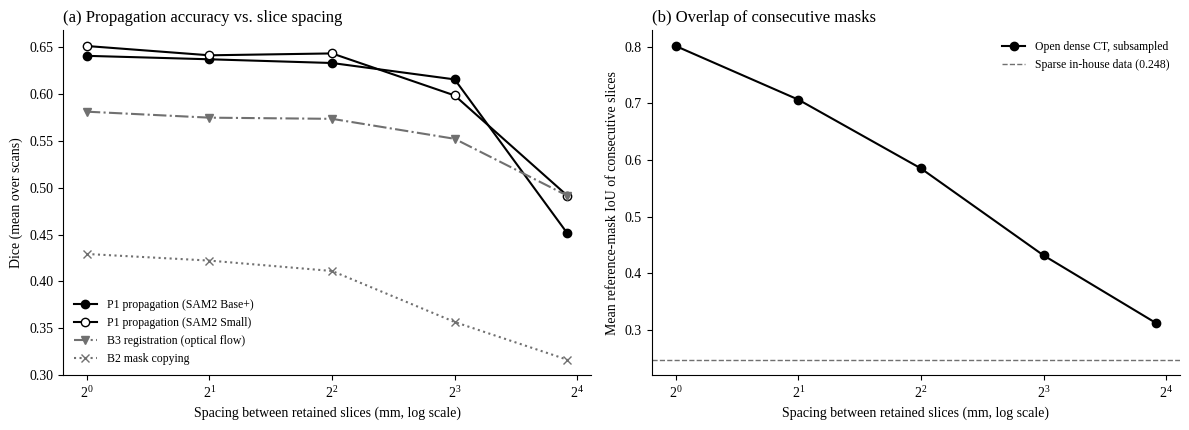

Bitti. Ciktilar: /content/drive/MyDrive/pnx_ek_analizler


In [11]:
def tarama_ort(df):
    # Once tarama ici ortalama, sonra taramalar arasi ortalama (her tarama esit agirlikli)
    return df.groupby('tarama').dice.mean().mean()


satir = []
for adim, g in list(R[~R.oto_adim | R.adim.isin(ADIMLAR)].groupby('adim')) + [('oto (~5 kesit)', R[R.oto_adim])]:
    s = {'adim': adim, 'tarama': g.tarama.nunique(), 'ortalama adim (mm)': g.drop_duplicates('tarama').adim_mm.mean(),
         'ardisik referans IoU': g.drop_duplicates('tarama').ardisik_iou_ort.mean(),
         'ardisik goruntu korelasyonu': g.drop_duplicates('tarama').ardisik_kor_ort.mean()}
    for y in ('P1_B+', 'P1_S', 'B3', 'B2'):
        gy = g[g.yontem == y]
        s[f'{y} Dice (tarama ort.)'] = tarama_ort(gy); s[f'{y} Dice (kesit ort.)'] = gy.dice.mean(); s[f'{y} n kesit'] = len(gy)
    a = g[g.yontem == 'P1_B+'].set_index(['tarama', 'z']).dice; b = g[g.yontem == 'B3'].set_index(['tarama', 'z']).dice.loc[a.index]
    pa, pb = a.groupby('tarama').mean(), b.groupby('tarama').mean()
    s['P1_B+ - B3 (tarama ort.)'] = (pa - pb).mean()
    s['p (Wilcoxon, tarama)'] = stats.wilcoxon(pa, pb).pvalue if len(pa) >= 5 and (pa != pb).any() else np.nan
    satir.append(s)
T = pd.DataFrame(satir)
T.to_csv(f'{OUT_DIR}/TABLO_ek8_seyreltme.csv', index=False)
display(T.round(3))

kutu = [0, 5, 10, 20, 40, 80, 1e9]
U = R[R.adim == 1].copy()
U['uzaklik_aralik'] = pd.cut(U.uzaklik_mm, kutu, labels=['0-5', '5-10', '10-20', '20-40', '40-80', '>80'])
TU = U.pivot_table(index='uzaklik_aralik', columns='yontem', values='dice', aggfunc='mean', observed=False)
TU['n kesit'] = U[U.yontem == 'P1_B+'].groupby('uzaklik_aralik', observed=False).size()
TU.to_csv(f'{OUT_DIR}/TABLO_ek8_uzaklik_mm.csv')
display(TU.round(3))

STIL = {'P1_B+': dict(color='black', marker='o', label='P1 propagation (SAM2 Base+)'),
        'P1_S': dict(color='black', marker='o', mfc='white', label='P1 propagation (SAM2 Small)'),
        'B3': dict(color='#707070', marker='v', ls='-.', label='B3 registration (optical flow)'),
        'B2': dict(color='#707070', marker='x', ls=':', label='B2 mask copying')}
Ts = T[T.adim.isin(ADIMLAR)].copy(); Ts['adim'] = Ts.adim.astype(int)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for y, st in STIL.items():
    ax[0].plot(Ts['ortalama adim (mm)'], Ts[f'{y} Dice (tarama ort.)'], **st)
ax[0].set_xscale('log', base=2); ax[0].set_xlabel('Spacing between retained slices (mm, log scale)'); ax[0].set_ylabel('Dice (mean over scans)')
ax[0].set_title('(a) Propagation accuracy vs. slice spacing', loc='left'); ax[0].legend(fontsize=8.5, frameon=False)
ax[1].plot(Ts['ortalama adim (mm)'], Ts['ardisik referans IoU'], color='black', marker='o', label='Open dense CT, subsampled')
ax[1].axhline(0.248, color='#707070', ls='--', lw=1, label='Sparse in-house data (0.248)')
ax[1].set_xscale('log', base=2); ax[1].set_xlabel('Spacing between retained slices (mm, log scale)')
ax[1].set_ylabel('Mean reference-mask IoU of consecutive slices'); ax[1].set_title('(b) Overlap of consecutive masks', loc='left')
ax[1].legend(fontsize=8.5, frameon=False)
for a in ax:
    a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
plt.tight_layout()
for uz in ('png', 'pdf'):
    plt.savefig(f'{OUT_DIR}/Figure_ek8_sparsification.{uz}', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Bitti. Ciktilar:', OUT_DIR)